In [1]:
{
 "cells": [],
 "metadata": {},
 "nbformat": 4,
 "nbformat_minor": 5
}

{'cells': [], 'metadata': {}, 'nbformat': 4, 'nbformat_minor': 5}

In [2]:
import os, time, random
import numpy as np
import torch, torch.nn as nn
from torch.utils.data import Subset, DataLoader
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Using: cuda


In [3]:
raw = datasets.EuroSAT(root="data", download=True, transform=transforms.ToTensor())
labels = np.array([y for _, y in raw.samples])
classes = raw.classes
print(len(raw), "images,", len(classes), "classes:", classes)

idx = np.arange(len(raw))
train_idx, temp_idx = train_test_split(idx, test_size=0.30, stratify=labels, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=labels[temp_idx], random_state=SEED)
print(len(train_idx), len(val_idx), len(test_idx))   # ~18900 / 4050 / 4050

100%|██████████| 94.3M/94.3M [00:00<00:00, 140MB/s]


27000 images, 10 classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
18900 4050 4050


In [4]:
np.savez("splits.npz", train=train_idx, val=val_idx, test=test_idx)

In [5]:
loader = DataLoader(Subset(raw, train_idx), batch_size=256, shuffle=False)
n, s, s2 = 0, torch.zeros(3), torch.zeros(3)
for x, _ in loader:
    n += x.numel() / 3
    s += x.sum(dim=[0, 2, 3])
    s2 += (x ** 2).sum(dim=[0, 2, 3])
mean = s / n
std = (s2 / n - mean ** 2).sqrt()
print("mean:", mean, "std:", std)

mean: tensor([0.3439, 0.3800, 0.4075]) std: tensor([0.2024, 0.1367, 0.1154])


In [6]:
norm = transforms.Normalize(mean.tolist(), std.tolist())

train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(), norm,
])
eval_tf = transforms.Compose([transforms.ToTensor(), norm])

train_ds = Subset(datasets.EuroSAT("data", transform=train_tf), train_idx)
val_ds   = Subset(datasets.EuroSAT("data", transform=eval_tf),  val_idx)
test_ds  = Subset(datasets.EuroSAT("data", transform=eval_tf),  test_idx)

BATCH = 64
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=BATCH, shuffle=False, num_workers=2)

In [7]:
class ModelA(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),   nn.ReLU(), nn.MaxPool2d(2),   # 32x32x16
            nn.Conv2d(16, 32, 3, padding=1),  nn.ReLU(), nn.MaxPool2d(2),   # 16x16x32
            nn.Conv2d(32, 64, 3, padding=1),  nn.ReLU(), nn.MaxPool2d(2),   # 8x8x64
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 4x4x128
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 64), nn.ReLU(),
            nn.Linear(64, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model_a = ModelA().to(device)

In [8]:
# Shape trace: confirms each layer's output matches your hand-drawn table
x = torch.randn(1, 3, 64, 64).to(device)
for layer in list(model_a.features) + list(model_a.classifier):
    x = layer(x)
    print(f"{layer.__class__.__name__:10s} -> {tuple(x.shape)}")

# Per-layer parameter count
total = 0
for name, p in model_a.named_parameters():
    print(f"{name:25s} {p.numel():>8,}")
    total += p.numel()
print("Total trainable:", f"{total:,}")   # expect 229,226

Conv2d     -> (1, 16, 64, 64)
ReLU       -> (1, 16, 64, 64)
MaxPool2d  -> (1, 16, 32, 32)
Conv2d     -> (1, 32, 32, 32)
ReLU       -> (1, 32, 32, 32)
MaxPool2d  -> (1, 32, 16, 16)
Conv2d     -> (1, 64, 16, 16)
ReLU       -> (1, 64, 16, 16)
MaxPool2d  -> (1, 64, 8, 8)
Conv2d     -> (1, 128, 8, 8)
ReLU       -> (1, 128, 8, 8)
MaxPool2d  -> (1, 128, 4, 4)
Flatten    -> (1, 2048)
Linear     -> (1, 64)
ReLU       -> (1, 64)
Linear     -> (1, 10)
features.0.weight              432
features.0.bias                 16
features.3.weight            4,608
features.3.bias                 32
features.6.weight           18,432
features.6.bias                 64
features.9.weight           73,728
features.9.bias                128
classifier.1.weight        131,072
classifier.1.bias               64
classifier.3.weight            640
classifier.3.bias               10
Total trainable: 229,226


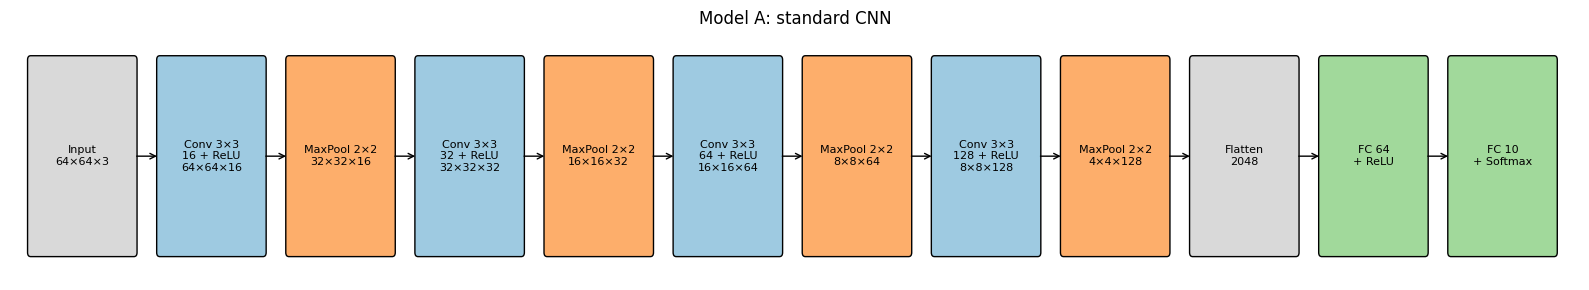

In [13]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

blocks = [
    ("Input\n64×64×3",              "#d9d9d9"),
    ("Conv 3×3\n16 + ReLU\n64×64×16",   "#9ecae1"),
    ("MaxPool 2×2\n32×32×16",       "#fdae6b"),
    ("Conv 3×3\n32 + ReLU\n32×32×32",   "#9ecae1"),
    ("MaxPool 2×2\n16×16×32",       "#fdae6b"),
    ("Conv 3×3\n64 + ReLU\n16×16×64",   "#9ecae1"),
    ("MaxPool 2×2\n8×8×64",         "#fdae6b"),
    ("Conv 3×3\n128 + ReLU\n8×8×128",   "#9ecae1"),
    ("MaxPool 2×2\n4×4×128",        "#fdae6b"),
    ("Flatten\n2048",               "#d9d9d9"),
    ("FC 64\n+ ReLU",               "#a1d99b"),
    ("FC 10\n+ Softmax",            "#a1d99b"),
]

fig, ax = plt.subplots(figsize=(16, 3))
w, gap = 1.0, 0.25
for i, (label, color) in enumerate(blocks):
    x = i * (w + gap)
    ax.add_patch(FancyBboxPatch((x, 0), w, 1.4, boxstyle="round,pad=0.03",
                                fc=color, ec="black", lw=1))
    ax.text(x + w / 2, 0.7, label, ha="center", va="center", fontsize=8)
    if i < len(blocks) - 1:
        ax.annotate("", xy=(x + w + gap, 0.7), xytext=(x + w, 0.7),
                    arrowprops=dict(arrowstyle="->", lw=1))

ax.set_xlim(-0.2, len(blocks) * (w + gap))
ax.set_ylim(-0.2, 1.6)
ax.axis("off")
ax.set_title("Model A: standard CNN", fontsize=12)
plt.tight_layout()
plt.savefig("modelA_architecture.png", dpi=200, bbox_inches="tight")
plt.show()

In [9]:
import json, copy
import torch.nn.functional as F

criterion = nn.CrossEntropyLoss()   # softmax is built into this loss

def evaluate(model, loader):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += criterion(out, y).item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n


def train_model(model, optimizer, epochs=25, name="model"):
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "epoch_time": []}
    best_val_loss, best_state = float("inf"), None

    for epoch in range(1, epochs + 1):
        model.train()
        t0 = time.time()
        run_loss, correct, n = 0.0, 0, 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()

            run_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)

        epoch_time = time.time() - t0          # training time only (excludes validation)
        train_loss, train_acc = run_loss / n, correct / n
        val_loss, val_acc = evaluate(model, val_loader)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["epoch_time"].append(epoch_time)

        # keep the weights with the lowest validation loss
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())

        print(f"[{name}] Epoch {epoch:02d}/{epochs} | "
              f"train loss {train_loss:.4f} acc {train_acc:.3f} | "
              f"val loss {val_loss:.4f} acc {val_acc:.3f} | {epoch_time:.1f}s")

    model.load_state_dict(best_state)          # restore best weights for testing
    with open(f"history_{name}.json", "w") as f:
        json.dump(history, f)
    return history

In [10]:
# Fresh model with a fixed seed, so every optimizer in Q3 starts from identical weights
torch.manual_seed(SEED)
model_a = ModelA().to(device)

optimizer = torch.optim.Adam(model_a.parameters(), lr=1e-3)
hist_a = train_model(model_a, optimizer, epochs=25, name="modelA_adam")

print(f"Average time per epoch: {np.mean(hist_a['epoch_time']):.2f}s")

[modelA_adam] Epoch 01/25 | train loss 1.2134 acc 0.541 | val loss 0.8696 acc 0.678 | 12.3s
[modelA_adam] Epoch 02/25 | train loss 0.7540 acc 0.720 | val loss 0.6627 acc 0.765 | 10.2s
[modelA_adam] Epoch 03/25 | train loss 0.6293 acc 0.770 | val loss 0.7494 acc 0.730 | 11.0s
[modelA_adam] Epoch 04/25 | train loss 0.5596 acc 0.799 | val loss 0.5098 acc 0.819 | 10.3s
[modelA_adam] Epoch 05/25 | train loss 0.4804 acc 0.830 | val loss 0.4898 acc 0.826 | 10.2s
[modelA_adam] Epoch 06/25 | train loss 0.4292 acc 0.849 | val loss 0.4296 acc 0.848 | 10.5s
[modelA_adam] Epoch 07/25 | train loss 0.3923 acc 0.864 | val loss 0.3771 acc 0.865 | 11.0s
[modelA_adam] Epoch 08/25 | train loss 0.3551 acc 0.879 | val loss 0.3413 acc 0.879 | 10.5s
[modelA_adam] Epoch 09/25 | train loss 0.3443 acc 0.879 | val loss 0.3774 acc 0.863 | 12.7s
[modelA_adam] Epoch 10/25 | train loss 0.2945 acc 0.897 | val loss 0.3065 acc 0.893 | 10.6s
[modelA_adam] Epoch 11/25 | train loss 0.2693 acc 0.904 | val loss 0.3028 acc 0.

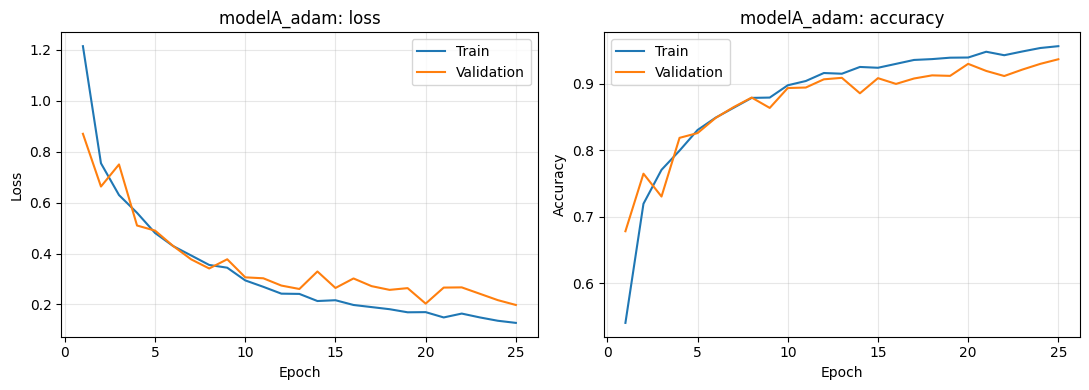

In [11]:
import matplotlib.pyplot as plt

def plot_history(h, title):
    ep = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(ep, h["train_loss"], label="Train")
    ax[0].plot(ep, h["val_loss"], label="Validation")
    ax[0].set(xlabel="Epoch", ylabel="Loss", title=f"{title}: loss")
    ax[0].legend(); ax[0].grid(alpha=0.3)
    ax[1].plot(ep, h["train_acc"], label="Train")
    ax[1].plot(ep, h["val_acc"], label="Validation")
    ax[1].set(xlabel="Epoch", ylabel="Accuracy", title=f"{title}: accuracy")
    ax[1].legend(); ax[1].grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"curves_{title}.png", dpi=150)
    plt.show()

plot_history(hist_a, "modelA_adam")

In [12]:
test_loss, test_acc = evaluate(model_a, test_loader)
print(f"Test loss {test_loss:.4f} | Test accuracy {test_acc:.4f}")

torch.save(model_a.state_dict(), "model_a_adam.pt")
print(f"Model size: {os.path.getsize('model_a_adam.pt') / 1024:.1f} KB")

Test loss 0.1732 | Test accuracy 0.9417
Model size: 900.5 KB


for **Q3**

In [ ]:


torch.manual_seed(SEED); model_mom = ModelA().to(device)
opt = torch.optim.SGD(model_mom.parameters(), lr=0.01, momentum=0.9)
hist_mom = train_model(model_mom, opt, epochs=25, name="modelA_sgd_momentum")

[modelA_sgd] Epoch 01/25 | train loss 2.2222 acc 0.174 | val loss 1.9582 acc 0.232 | 11.3s
[modelA_sgd] Epoch 02/25 | train loss 1.8064 acc 0.288 | val loss 1.7554 acc 0.320 | 10.4s
[modelA_sgd] Epoch 03/25 | train loss 1.4870 acc 0.413 | val loss 1.3895 acc 0.443 | 10.3s
[modelA_sgd] Epoch 04/25 | train loss 1.2814 acc 0.517 | val loss 1.5299 acc 0.451 | 10.4s
[modelA_sgd] Epoch 05/25 | train loss 1.1320 acc 0.586 | val loss 1.1853 acc 0.555 | 10.3s
[modelA_sgd] Epoch 06/25 | train loss 1.0089 acc 0.632 | val loss 1.4525 acc 0.508 | 10.3s
[modelA_sgd] Epoch 07/25 | train loss 0.9134 acc 0.665 | val loss 0.9020 acc 0.671 | 11.2s
[modelA_sgd] Epoch 08/25 | train loss 0.8533 acc 0.689 | val loss 1.0613 acc 0.612 | 10.2s
[modelA_sgd] Epoch 09/25 | train loss 0.7986 acc 0.705 | val loss 1.0276 acc 0.621 | 10.6s
[modelA_sgd] Epoch 10/25 | train loss 0.7674 acc 0.719 | val loss 0.8668 acc 0.682 | 10.2s
[modelA_sgd] Epoch 11/25 | train loss 0.7382 acc 0.728 | val loss 0.7333 acc 0.727 | 10.4s

In [1]:
torch.manual_seed(SEED); model_sgd = ModelA().to(device)
opt = torch.optim.SGD(model_sgd.parameters(), lr=0.01)
hist_sgd = train_model(model_sgd, opt, epochs=25, name="modelA_sgd")

NameError: name 'torch' is not defined